# 01. 왜 미국 통계 하나로는 답할 수 없나 — 7개 원천과 데이터 품질

**미국 통계에서 이상 신호가 보였다.** 정책 후 12개월 한국산 화장품 수입 금액은 +11.7%인데 해상+항공 중량은 +39.5%, kg당 단가는 크게 떨어졌다.
이 데이터만으로 할 수 있는 해석과 할 수 없는 해석을 나누면, 무엇을 더 모아야 하는지가 정해진다.

| 미국 통계만으로 답할 수 없는 질문 | 필요한 원천 | 이 프로젝트의 원천 |
|---|---|---|
| 한국만의 변화인가, 미국 화장품 수입 전체의 변화인가 | 같은 정의의 다른 나라 통계 | Census 비교 8개국 |
| 소포가 통계에 새로 잡힌 것인가 | 같은 흐름의 다른 쪽 기록 | 관세청 대미 수출 |
| 환율 때문인가 | 월별 환율 | Federal Reserve Board G.5 7개 통화 |
| 어느 항만으로 들어오나 | 하역항별 통계 | Census 하역항 × HS6 |
| 운송에 얼마나 걸리나 | 선박의 출항·입항 기록 | PORT-MIS × CBP CF-1400 |

이 노트북은 7개 원천의 역할과 규모를 먼저 보고, 이후 노트북(02~06)의 결론이 서는 데이터 품질을 확인한다: 자동 품질 검사(dbt), 결측·0값, 이상치, 분포, 선박 연결 품질.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from kbeauty import report, warehouse
from kbeauty.paths import REPO, TABLES_DIR
from kbeauty.viz import annotations as an
from kbeauty.viz import notebook as nbviz
from kbeauty.viz.theme import COLORS as C

%matplotlib inline
nbviz.setup()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_rows", 60)
load = lambda t: warehouse.load(t).pipe(lambda d: d.assign(**{c: pd.to_datetime(d[c]) for c in ("month",) if c in d}))
us = load("stg_census__hs10_monthly")
ports = load("stg_census__port_hs6_monthly")
peers = load("stg_census__peer_hs10_monthly")
kr = load("stg_kcs__kr_exports_us")
fx = load("stg_fed_board__fx_monthly")
vessel = warehouse.load("stg_vessel__routes")
summary = load("mart_monthly_summary")

## 1. 7개 원천과 각 원천의 역할

In [2]:
def span(d, col="month"):
    return f"{d[col].min():%Y-%m} ~ {d[col].max():%Y-%m}"

sources = pd.DataFrame([
    {"원천": "Census 한국산 수입 (HS10)", "단위": "HS10 × 월", "행": len(us), "기간": span(us), "키 수": us.hs10.nunique()},
    {"원천": "Census 한국산 수입 (하역항)", "단위": "하역항 × HS6 × 월", "행": len(ports), "기간": span(ports), "키 수": ports.port_code.nunique()},
    {"원천": "Census 비교국 수입 (HS10)", "단위": "국가 × HS10 × 월", "행": len(peers), "기간": span(peers), "키 수": peers.cty_code.nunique()},
    {"원천": "관세청 한국 → 미국 수출 (HSK10)", "단위": "HSK10 × 월", "행": len(kr), "기간": span(kr), "키 수": kr.hsk10.nunique()},
    {"원천": "Fed Board 환율", "단위": "통화 × 월", "행": len(fx), "기간": span(fx), "키 수": fx.currency.nunique()},
    {"원천": "부산 출항 × 미국 입항 신고 (선박)", "단위": "선박 1회 운항", "행": len(vessel),
     "기간": f"{pd.to_datetime(vessel.us_filing_date).min():%Y-%m} ~ {pd.to_datetime(vessel.us_filing_date).max():%Y-%m}",
     "키 수": vessel.call_sign.nunique()},
])
raw_files = sorted(p.relative_to(REPO).as_posix() for p in (REPO / "data" / "raw").rglob("*") if p.is_file())
print(f"보관된 원문 파일 {len(raw_files)}개, 해시 기록 {len((REPO / 'data' / 'SHA256SUMS').read_text().splitlines())}개")
sources

보관된 원문 파일 82개, 해시 기록 88개


,원천,단위,행,기간,키 수
0,Census 한국산 수입 (HS10),HS10 × 월,685,2024-01 ~ 2026-08,22
1,Census 한국산 수입 (하역항),하역항 × HS6 × 월,5645,2024-01 ~ 2026-08,83
2,Census 비교국 수입 (HS10),국가 × HS10 × 월,5450,2024-01 ~ 2026-08,8
3,관세청 한국 → 미국 수출 (HSK10),HSK10 × 월,1046,2024-01 ~ 2026-09,32
4,Fed Board 환율,통화 × 월,315,2023-01 ~ 2026-09,7
5,부산 출항 × 미국 입항 신고 (선박),선박 1회 운항,1005,2024-04 ~ 2026-09,517


**발견**: 원천은 **7개**(기관 5곳)이고, 분석에는 위 표의 6개 데이터 파일로 들어온다.
CF-1400(미국 CBP)과 PORT-MIS(해양수산부)는 공통 식별자가 없어 선박 단위로 연결한 관측치 한 파일이 되기 때문이다.

| # | 원천 | 기관 | 데이터 파일 | 단위 | 행 | 기간 |
|---|---|---|---|---|---|---|
| 1 | [수입 통계 `imports/hs`](https://api.census.gov/data/timeseries/intltrade/imports/hs.html) (한국산) | 미국 Census | Census 한국산 수입 | HS10 22개 × 월 | 685 | 2024-01 ~ 2026-08 |
| 2 | [수입 통계 `imports/porths`](https://api.census.gov/data/timeseries/intltrade/imports/porths.html) (한국산) | 미국 Census | Census 하역항 | 하역항 83곳 × HS6 × 월 | 5,645 | 2024-01 ~ 2026-08 |
| 3 | [CF-1400 외국 무역선 입항 기록](https://www.cbp.gov/document/report/cf-1400-record-vessel-foreign-trade-entrances) | 미국 CBP | 선박 연결 관측치 | 선박 1회 운항 | 1,005 | 2024-04 ~ 2026-09 |
| 4 | [PORT-MIS 선박운항정보](https://www.data.go.kr/data/15006353/openapi.do) | 해양수산부 | (3과 같은 파일) | | | |
| 5 | [수입 통계 `imports/hs`](https://api.census.gov/data/timeseries/intltrade/imports/hs.html) (비교 8개국) | 미국 Census | Census 비교국 | 8개국 × HS10 × 월 | 5,450 | 2024-01 ~ 2026-08 |
| 6 | [품목별 국가별 수출입실적(GW)](https://www.data.go.kr/data/15100475/openapi.do) | 관세청 | 관세청 한국 → 미국 수출 | HSK10 32개 × 월 | 1,046 | 2024-01 ~ **2026-09** |
| 7 | 월평균 환율 7개 통화([G.5](https://www.federalreserve.gov/releases/h10/current/default.htm), 릴리스 XML) | Federal Reserve Board | Fed Board 환율 | 7개 통화 × 월 | 315 | 2023-01 ~ 2026-09 |

- 한국 측 통계가 미국보다 한 달 빨리 공개되어 2026-09까지 있다. 05 노트북에서 선행 지표로 쓴다.
- 보관된 원문 파일 82개 중 설명 문서 1개를 뺀 81개와 추출 CSV 7개, 모두 88개 파일의 SHA-256이 기록되어 있다. 환율은 최초 분석에서 FRED를 통해 접근한 Board G.5 계열을 썼고, 2026-11-06부터 Federal Reserve Board 릴리스 XML 직접 수집으로 교체했다(전 기간 값 동일, `docs/experiments/fred_to_federal_reserve_board.md`).

## 2. 자동 품질 검사 (dbt)

`scripts/run_all.py`가 실행한 dbt build의 결과 파일(`warehouse/target/run_results.json`)을 읽는다. 모델과 데이터 테스트가 모두 통과해야 분석이 시작된다.

In [3]:
rr = json.loads((REPO / "warehouse" / "target" / "run_results.json").read_text(encoding="utf-8"))
res = pd.DataFrame([{"node": r["unique_id"].split(".")[-1] if r["unique_id"].startswith("test.") else r["unique_id"].split(".")[-1],
                     "type": r["unique_id"].split(".")[0], "status": r["status"]} for r in rr["results"]])
print(res.groupby(["type", "status"]).size().to_string())
singular = res[(res.type == "test") & res.node.str.startswith("assert_")]
singular[["node", "status"]].reset_index(drop=True)

type   status 
model  success    16
seed   success     5
test   pass       49


,node,status
0,assert_mode_values_within_total,pass
1,assert_months_contiguous,pass
2,assert_port_totals_reconcile_to_national,pass
3,assert_fx_covers_panel,pass
4,assert_kr_exports_months_contiguous,pass
5,assert_peer_panel_complete,pass
6,assert_country_panel_balanced,pass
7,assert_transit_days_plausible,pass
8,assert_mirror_preserves_totals,pass
9,assert_weight_present_when_value_present,pass


**발견**: 모델 16개, 시드 5개, 데이터 테스트 49개가 모두 통과했다. 분석의 전제가 되는 주요 검사는 다음과 같다.

- **하역항 합계 = 전국 합계**(1달러 단위): Census 두 엔드포인트가 서로 맞는다.
- **월 연속성**: 미국 32개월, 한국 33개월에 빠진 달이 없다.
- **패널 균형**: 9개국 × 32개월이 모두 있다.
- **환율 커버리지**: 모든 국가·월에 환율이 있다.
- **미러 합계 보존**: 한국·미국 양쪽 금액이 마트에서 1달러도 빠지지 않는다.
- **리드타임 범위**: 통계에 쓰는 선박 관측치가 모두 5~60일 안에 있다.
- **해상·항공 금액 ≤ 총액**, **금액이 있으면 중량도 있음**.

## 3. 결측과 0값

Census는 값이 0인 품목×월 행을 내려주지 않는다. 따라서 '행이 없음'은 결측이 아니라 0이다. 품목별로 32개월 중 몇 달에 값이 있는지 본다.

In [4]:
n_months = us.month.nunique()
cover = (us.groupby("hs10").agg(months_with_value=("month", "nunique"), value_musd=("value_usd", lambda s: s.sum() / 1e6))
           .assign(coverage=lambda d: d.months_with_value / n_months).sort_values("value_musd", ascending=False))
cover["share_of_value"] = cover.value_musd / cover.value_musd.sum()
print("US HS10 lines present every month:", int((cover.coverage == 1).sum()), "of", len(cover),
      "| value share of lines with gaps:", round(cover.loc[cover.coverage < 1, "share_of_value"].sum(), 4))
cover

US HS10 lines present every month: 18 of 22 | value share of lines with gaps: 0.0003


,months_with_value,value_musd,coverage,share_of_value
hs10,,,,
3304995000,32,"3,635.864",1.000,0.675
3304100000,32,590.879,1.000,0.110
3304200000,32,311.465,1.000,0.058
3304991000,32,220.113,1.000,0.041
3307900000,32,203.395,1.000,0.038
3305900000,32,191.346,1.000,0.036
3305100000,32,82.686,1.000,0.015
3304910050,32,50.645,1.000,0.009
3304300000,32,47.500,1.000,0.009


In [5]:
mode_gap = pd.DataFrame({
    "other (육로·우편·미상) 금액 비중": [us.other_value_usd.sum() / us.value_usd.sum()],
    "해상 금액은 있는데 해상 중량 0인 행": [int(((us.vessel_value_usd > 0) & (us.vessel_weight_kg == 0)).sum())],
    "항공 금액은 있는데 항공 중량 0인 행": [int(((us.air_value_usd > 0) & (us.air_weight_kg == 0)).sum())],
    "그 행들의 금액 합 (달러)": [int(us.loc[((us.vessel_value_usd > 0) & (us.vessel_weight_kg == 0)), "vessel_value_usd"].sum()
                                  + us.loc[((us.air_value_usd > 0) & (us.air_weight_kg == 0)), "air_value_usd"].sum())],
}).T.rename(columns={0: "값"})
mode_gap

,값
other (육로·우편·미상) 금액 비중,0.014
해상 금액은 있는데 해상 중량 0인 행,0.000
항공 금액은 있는데 항공 중량 0인 행,0.000
그 행들의 금액 합 (달러),0.000


**발견**:
- 미국 HS10 22개 중 **18개가 32개월 내내** 값이 있다. 빈 달이 있는 4개(면도용품, 탈취제, 향 등)는 금액 비중 합계가 **0.03%다**.
  Census는 값이 0인 행을 내려주지 않으므로 이 빈 달은 결측이 아니라 0으로 처리한다.
- 해상·항공이 아닌 'other'(육로·우편·미상)는 금액의 **1.4%뿐이다**. 중량은 해상·항공만 공개되므로, kg당 단가가 이 1.4%를 빼고 계산된다는 한계는 작다.
- 해상이나 항공 금액이 있는데 중량이 0인 행은 **없다**. kg당 단가 계산에 0으로 나누는 문제가 없다.

**판단**: 결측 처리로 결론이 바뀔 여지는 없다.

## 4. 이상치

**4-1. 월별 합계**: 계절성이 있으므로 전년 동월 대비 로그 성장률(YoY)을 기준으로, 중앙값에서 MAD(중앙값 절대 편차)의 3배 이상 벗어난 달을 표시한다.

flagged months:
Empty DataFrame
Columns: [value_usd, measured_weight_kg, vessel_weight_kg, air_weight_kg]
Index: []


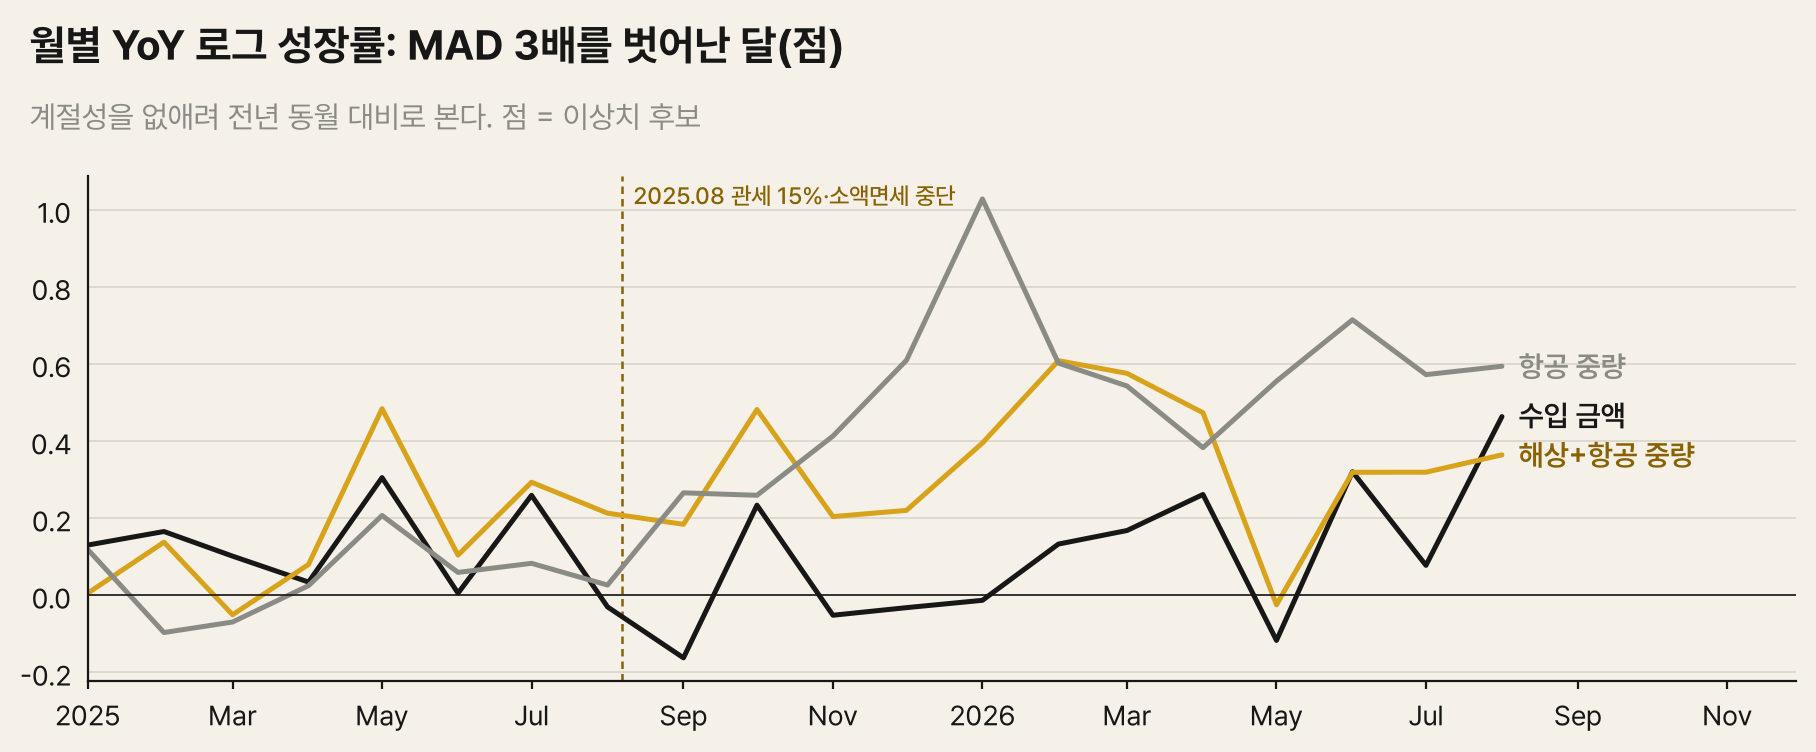

In [6]:
s = summary.set_index("month")
def mad_flags(x, k=3.0):
    med = x.median(); mad = (x - med).abs().median() * 1.4826
    return (x - med).abs() > k * mad
yoy = np.log(s[["value_usd", "measured_weight_kg", "vessel_weight_kg", "air_weight_kg"]]).diff(12).dropna()
flags = yoy.apply(mad_flags)
print("flagged months:")
print(yoy[flags.any(axis=1)].round(3).to_string())
fig, ax = nbviz.figure(title="월별 YoY 로그 성장률: MAD 3배를 벗어난 달(점)", subtitle="계절성을 없애려 전년 동월 대비로 본다. 점 = 이상치 후보")
items = []
for c, color, name in (("value_usd", C["ink"], "수입 금액"), ("measured_weight_kg", C["primary"], "해상+항공 중량"), ("air_weight_kg", C["muted"], "항공 중량")):
    ax.plot(yoy.index, yoy[c], color=color, lw=1.8)
    ax.scatter(yoy.index[flags[c]], yoy.loc[flags[c], c], color=color, s=55, zorder=3, edgecolor=C["ink"])
    items.append((yoy.index[-1], yoy[c].iloc[-1], name, C["primary_dark"] if color == C["primary"] else color, 600))
ax.axhline(0, color=C["ink"], lw=0.6)
an.policy_marker(ax)
ax.set_xlim(yoy.index.min(), yoy.index.max() + pd.Timedelta(days=120))
an.end_labels(ax, items)
plt.show()

**4-2. 품목 × 월 단가**: 같은 HS10 안에서 kg당 단가가 그 품목의 중앙값에서 크게 벗어난 달(해상·항공 각각, 금액 10만 달러 이상인 행만).

In [7]:
fct = load("fct_imports_hs10_mode_monthly").query("mode != 'other' and value_usd >= 100000 and weight_kg > 0")
fct["log_uv"] = np.log(fct.value_usd / fct.weight_kg)
fct["robust_z"] = fct.groupby(["hs10", "mode"]).log_uv.transform(
    lambda x: (x - x.median()) / ((x - x.median()).abs().median() * 1.4826 + 1e-9))
out = fct[fct.robust_z.abs() > 4].sort_values("value_usd", ascending=False)
print(f"{len(out)} of {len(fct)} rows ({len(out) / len(fct):.1%}), value share {out.value_usd.sum() / fct.value_usd.sum():.2%}")
out[["month", "hs10", "category", "mode", "value_usd", "weight_kg", "unit_value_usd_per_kg", "robust_z"]].head(12)

1 of 652 rows (0.2%), value share 0.00%


,month,hs10,category,mode,value_usd,weight_kg,unit_value_usd_per_kg,robust_z
1248,2026-03-01,3303003000,fragrance,air,140752,82,"1,716.488",6.492


**발견**:
- **월별 합계**: 전년 대비 성장률 기준으로 MAD 3배를 넘는 달이 **없다**. 2025년 5월의 급증(전년 대비 금액 +36%)이나 2025년 9월 이후의 항공 중량 증가도
  이 기준으로는 이상치가 아니다. 즉 개별 달의 튀는 값이 아니라 **수준 자체가 이동**한 것이다. 이후 분석이 '특정 달'보다 '전후 평균'을 비교하는 이유다.
- **품목 × 월 단가**: 금액 10만 달러 이상인 652행 중 **1행(0.2%)만** 그 품목 중앙값에서 크게 벗어났다(2026-03 알코올 함유 향수 항공 82kg, kg당 1,717달러).
  금액 비중이 0.003%로, 결론에 영향을 주지 않는다. 제거하지 않고 그대로 둔다.

**판단**: 이상치 때문에 결론이 왜곡될 위험은 낮다. 단가 분해(02)와 정책 전후 비교(03·04)를 원자료 그대로 진행한다.

## 5. 분포

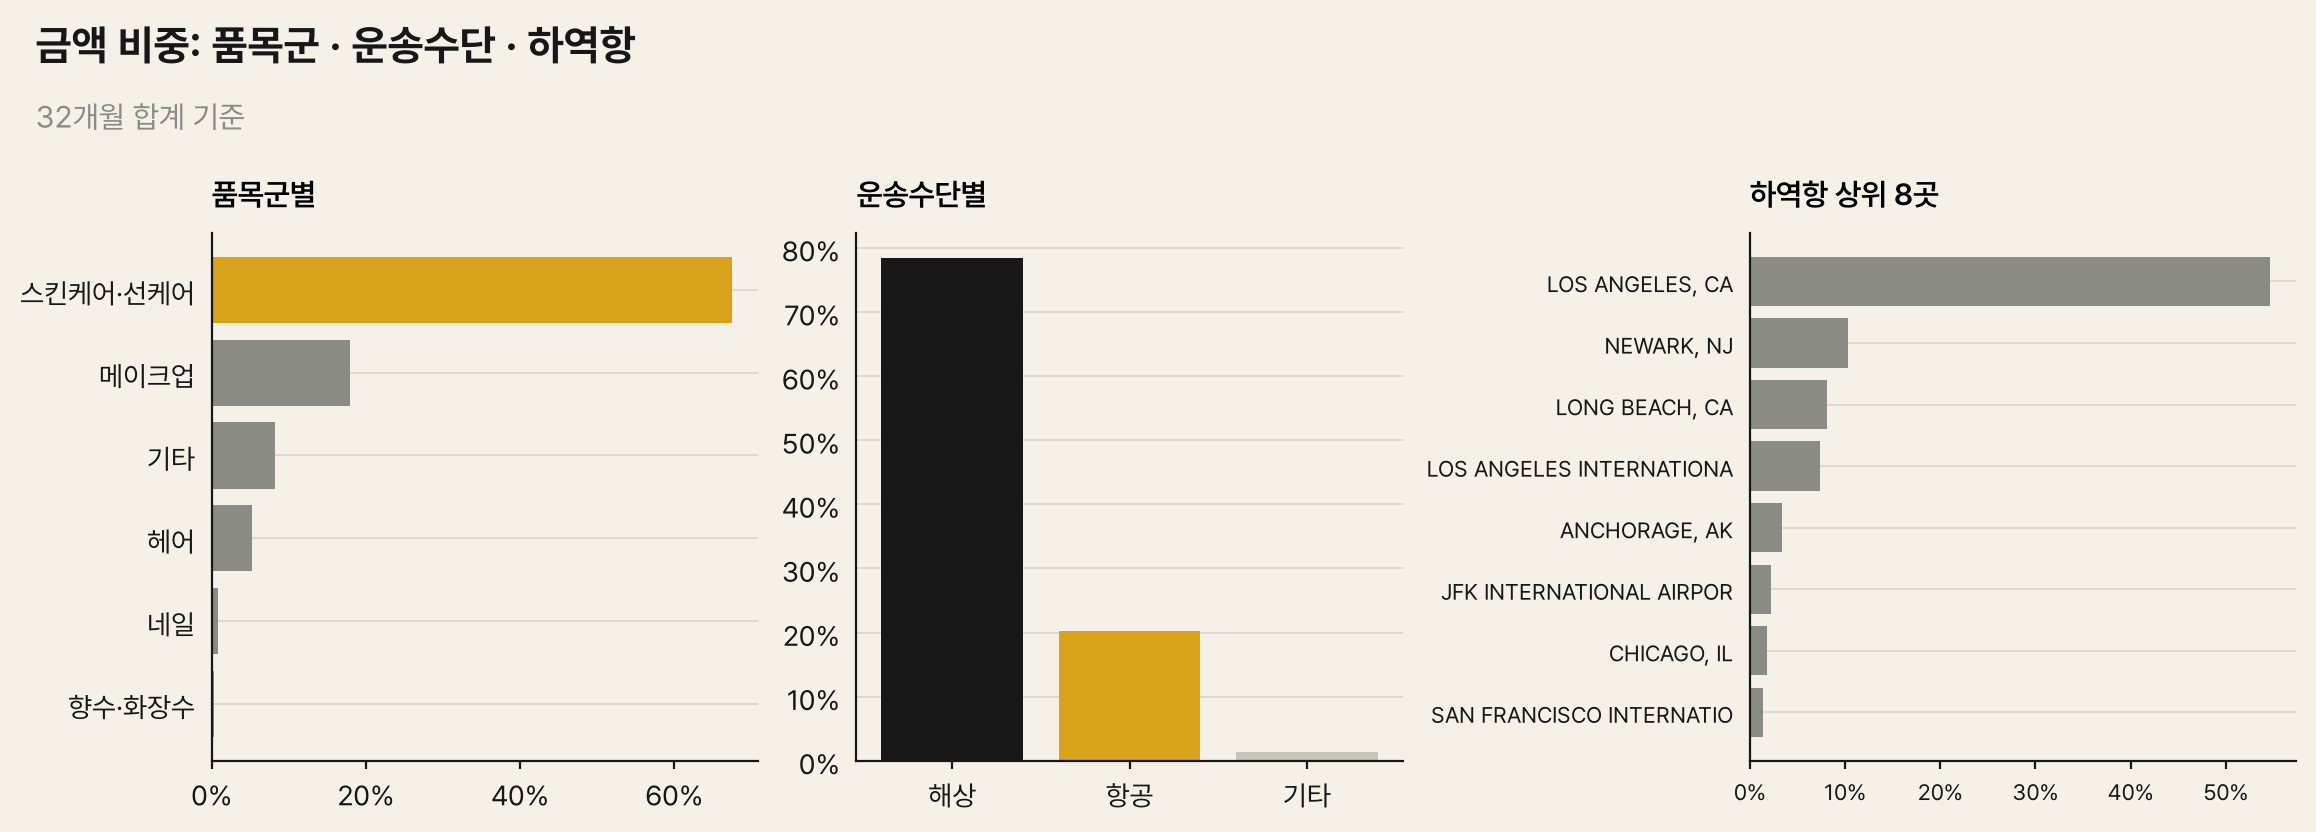

,category_share
category_ko,
스킨케어·선케어,0.675
메이크업,0.179
기타,0.082
헤어,0.052
네일,0.009
향수·화장수,0.003


In [8]:
from kbeauty.viz.formats import percent_axis
fig, axes = nbviz.figure("three_panel", 1, 3, title="금액 비중: 품목군 · 운송수단 · 하역항", subtitle="32개월 합계 기준")
cat = us.merge(warehouse.load("hs10_category"), on="hs10").groupby("category_ko").value_usd.sum().sort_values()
axes[0].barh(cat.index, cat / cat.sum(), color=[C["primary"] if v == cat.max() else C["muted"] for v in cat]); axes[0].set_title("품목군별")
modes = pd.Series({"해상": us.vessel_value_usd.sum(), "항공": us.air_value_usd.sum(), "기타": us.other_value_usd.sum()})
axes[1].bar(modes.index, modes / modes.sum(), color=[C["ink"], C["primary"], C["faint"]]); axes[1].set_title("운송수단별")
top_ports = ports.groupby("port_name").value_usd.sum().sort_values().tail(8)
axes[2].barh(top_ports.index.str.slice(0, 24), top_ports / ports.value_usd.sum(), color=C["muted"])
axes[2].set_title("하역항 상위 8곳"); axes[2].tick_params(labelsize=8)
percent_axis(axes[0], "x"); percent_axis(axes[1], "y"); percent_axis(axes[2], "x")
plt.show()
pd.DataFrame({"category_share": (cat / cat.sum()).sort_values(ascending=False)})

In [9]:
panel = warehouse.load("mart_country_panel_monthly")
countries = (panel.groupby("country").agg(value_bn=("value_usd", lambda s: s.sum() / 1e9),
                                          sea_air_share=("sea_air_share_value", "mean"),
                                          air_usd_per_kg=("air_usd_per_kg", "median"),
                                          vessel_usd_per_kg=("vessel_usd_per_kg", "median"))
             .sort_values("value_bn", ascending=False))
countries

,value_bn,sea_air_share,air_usd_per_kg,vessel_usd_per_kg
country,,,,
France,10.141,0.967,70.979,29.684
Korea,5.388,0.985,33.872,18.605
Italy,4.790,0.980,48.241,21.084
Canada,4.756,0.013,91.654,21.824
Mexico,3.525,0.009,57.730,5.316
China,2.378,0.980,18.945,4.100
United Kingdom,1.264,0.949,33.958,12.929
Germany,0.773,0.939,59.696,13.885
Japan,0.625,0.989,46.179,17.628


In [10]:
names = warehouse.load("stg_kcs__hsk10_names").set_index("hsk10").name_ko
kr_top = kr.groupby("hsk10").agg(export_musd=("export_usd", lambda s: s.sum() / 1e6), export_kt=("export_kg", lambda s: s.sum() / 1e6))
kr_top["usd_per_kg"] = kr_top.export_musd / kr_top.export_kt
kr_top["share"] = kr_top.export_musd / kr_top.export_musd.sum()
kr_top.insert(0, "name_ko", names.reindex(kr_top.index).values)
kr_top.sort_values("export_musd", ascending=False).head(10)

,name_ko,export_musd,export_kt,usd_per_kg,share
hsk10,,,,,
3304991000,기초화장용 제품류,"2,629.642",96.129,27.355,0.429
3304999000,기타,"1,483.798",55.736,26.622,0.242
3304109000,기타,397.000,7.181,55.283,0.065
3307909000,기타,338.100,83.610,4.044,0.055
3307904000,마스크 팩,305.718,21.786,14.033,0.050
3304992000,메이크업용 제품류,289.705,7.680,37.720,0.047
3305909000,기타,185.095,14.464,12.797,0.030
3304209000,기타,119.970,1.618,74.147,0.020
3305100000,샴푸,92.689,11.826,7.838,0.015


**발견**:
- **품목**: 스킨케어·선케어가 금액의 **67.5%**, 메이크업 17.9%, 기타 8.2%, 헤어 5.2%다. 스킨케어·선케어는 미국 HS10에서 한 세목(3304995000)이라, 세목 단위 분석의 해상도가 낮다(02에서 한국 HSK10으로 보완).
- **운송수단**: 해상 **78.4%**, 항공 20.2%, 기타 1.4%.
- **하역항**: LA 단독 54.6%, LA·롱비치·LA 공항까지 70.1%(06에서 집중 위험으로 다룬다).
- **비교국**: 한국은 9개국 중 프랑스(101억 달러) 다음으로 큰 수출국(54억 달러)이다. 캐나다·멕시코는 해상+항공 비중이 1% 안팎이라
  해상·항공 지표 비교에서 뺀다(03). 한국의 항공 kg당 단가 중앙값(34달러)은 영국과 비슷하고 프랑스(71달러)의 절반이다.
- **한국 측 세목**: 기초화장용 제품류(3304.99-1000)가 **43%**, 3304.99 기타가 24%, 마스크 팩이 5%다.

## 6. 선박 관측치: 리드타임 원천의 연결 품질

부산 출항(PORT-MIS)과 미국 입항 신고(CF-1400)는 공통 식별자가 없어 호출부호·선박명으로 연결했다. 연결 방식과 통계 사용 여부를 본다.

관측 1005건 중 통계 사용 661건 (66%)


use,제외,통계 사용,합계
match_method,,,
call_sign,183,530,713
vessel_name,98,61,159
call_sign_history,11,50,61
unmatched,46,0,46
vessel_name_call_sign_near,6,20,26


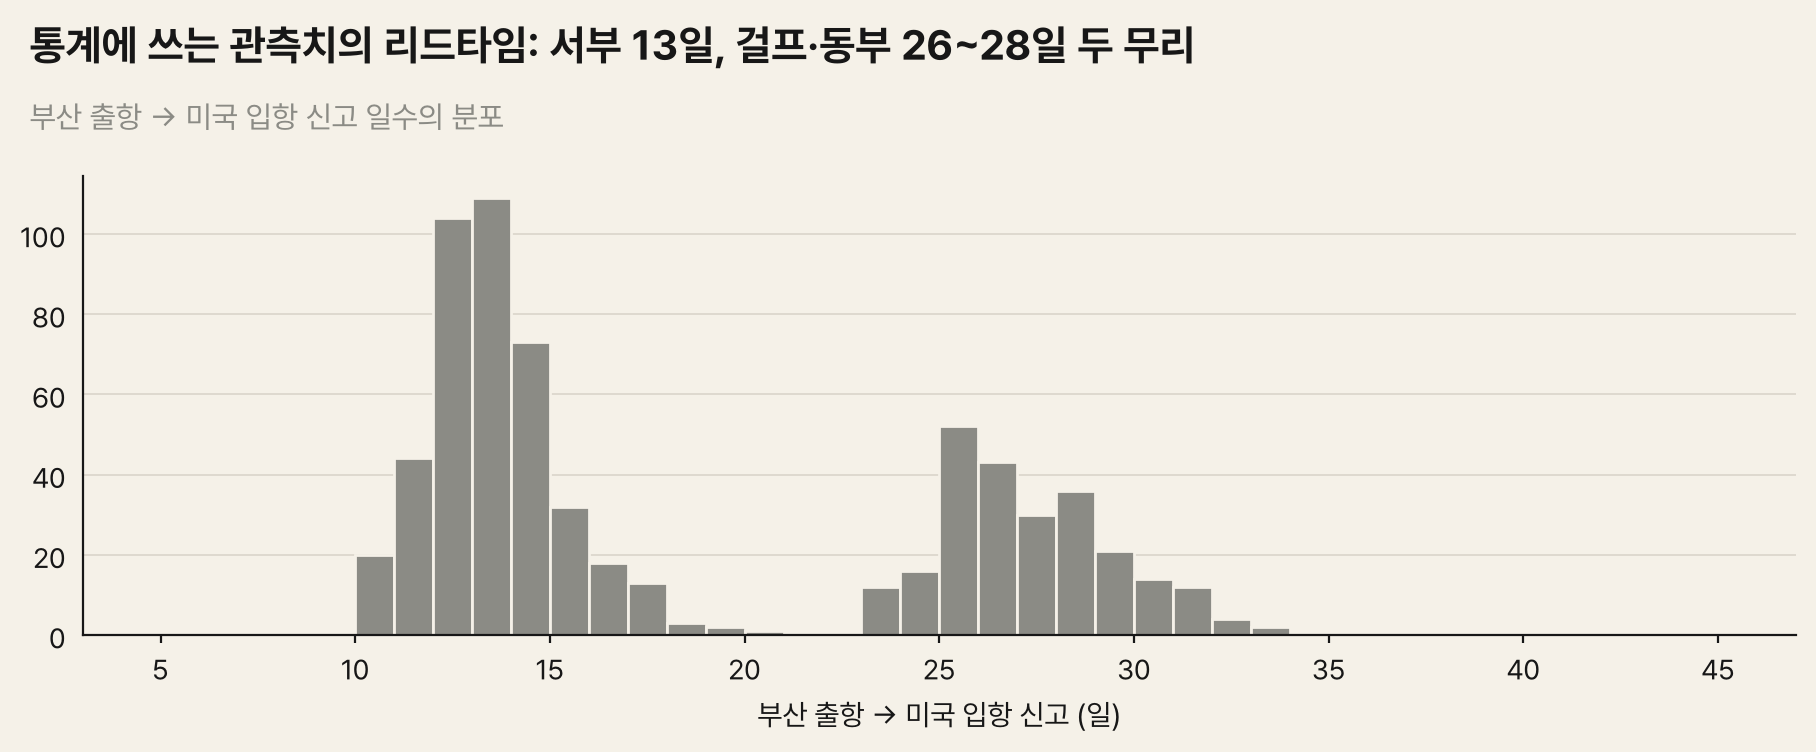

In [11]:
v = vessel.assign(use=vessel.use_for_stats.map({True: "통계 사용", False: "제외"}))
link = v.pivot_table(index="match_method", columns="use", values="observation_id", aggfunc="count", fill_value=0)
link["합계"] = link.sum(axis=1)
print(f"관측 {len(v)}건 중 통계 사용 {int(v.use_for_stats.sum())}건 ({v.use_for_stats.mean():.0%})")
display(link.sort_values("합계", ascending=False))
used = v[v.use_for_stats]
fig, ax = nbviz.figure(title="통계에 쓰는 관측치의 리드타임: 서부 13일, 걸프·동부 26~28일 두 무리", subtitle="부산 출항 → 미국 입항 신고 일수의 분포")
ax.hist(used.departure_to_filing_days, bins=range(5, 46), color=C["muted"], edgecolor=C["paper"])
ax.set_xlabel("부산 출항 → 미국 입항 신고 (일)")
plt.show()

**발견**:
- 관측 1,005건 중 **661건(66%)을** 통계에 쓴다.
- 호출부호로 연결된 713건 중 530건이 통계에 들어갔다. 선박명만으로 연결된 159건은 61건만 통과했다. 연결되지 않은 46건은 모두 제외했다.
- 리드타임 분포는 두 무리로 뚜렷이 나뉜다. 서부(13일 안팎)와 걸프·동부(26~28일)다. 06 노트북의 권역별 리드타임이 이 분포에서 나온다.

**판단**: 연결 등급과 이상치 검토를 통과한 관측만 쓰므로 리드타임 통계는 믿을 만하다. 다만 CF-1400 신고일의 공식 정의가 없어 '입항 신고까지'로 해석한다.

## 7. 일치 확인

이 노트북이 원천에서 직접 더한 월별 합계가 마트(`mart_monthly_summary`)와 `run_all` 표(`reports/tables/window_totals.csv`)와 같은지 확인한다.

In [12]:
direct = us.groupby("month").value_usd.sum()
assert (direct.values == summary.set_index("month").value_usd.reindex(direct.index).values).all()
wt = pd.read_csv(TABLES_DIR / "window_totals.csv").set_index("metric")
assert wt.loc["value_usd", "post_12m"] == direct.loc["2025-09-01":"2026-08-01"].sum()
print("source totals match mart_monthly_summary and reports/tables/window_totals.csv")

source totals match mart_monthly_summary and reports/tables/window_totals.csv


## 결론: 분석에 쓸 수 있는 것과 주의할 것

| 구분 | 내용 |
|---|---|
| **쓸 수 있다** | 원천 7개(데이터 파일 6개) 모두 해시 고정·오프라인 재현·dbt 49개 테스트 통과. 결측(0.03%)과 이상치(1행)는 결론에 영향 없음 |
| **주의 1** | 스킨케어·선케어가 미국 HS10 한 세목에 금액의 67.5%로 몰려 있다 → 세목 분석은 한국 HSK10으로 보완(02) |
| **주의 2** | 중량은 해상·항공만 공개(금액의 98.6%) → kg당 단가는 해상·항공 기준 |
| **주의 3** | 두 나라 세번 분류가 다르다(예: 마스크 팩) → 미러 비교는 세목보다 전체 합계로(04) |
| **주의 4** | 변화는 특정 달의 이상치가 아니라 수준 이동이다 → 전후 평균 비교와 위약 검정으로 다룬다(03·04) |
| **주의 5** | 리드타임은 '부산 출항 → 미국 입항 신고'까지이고, 통관·내륙 운송은 포함하지 않는다(06) |